# Data Analysis for E-commerce
### in this project we want to check all features and essential data during one year which the customer wants more than other product.
## Main Goals are how select best items and show all the product sale  for this website
## this is  a common project which will help you during your study about Data Analysis

In [3]:
from ctypes import kind
from inspect import stack
from multiprocessing.reduction import duplicate

# imports libs
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"]=(10,5)

In [5]:
t=pd.read_csv("data/customer_master.csv")
t.head()

,customer_id,customer_name,customer_age,gender,customer_segment,customer_city,customer_state,customer_country,region,customer_postal_code,customer_acquisition_cost
0,CUST-000001,Donna Miller,54,Female,Consumer,Laurenland,Dubai,UAE,South,11253,13.58
1,CUST-000002,Joseph James,61,Male,Consumer,Lake Peter,Lower Saxony,Germany,North,47778,27.45
2,CUST-000003,Daniel Smith,47,Male,Consumer,Seanview,North Rhine,Germany,West,13900,31.53
3,CUST-000004,David Lopez,30,Male,VIP,Hawkinshaven,Pennsylvania,USA,East,53984,16.02
4,CUST-000005,Dakota Davis,55,Female,Consumer,New Carlymouth,Florida,USA,South,50994,41.34


In [6]:
print(f"we have {t.shape[0]} customers and {t.shape[1]} columns")

we have 25000 customers and 11 columns


In [7]:
t.isna().sum()

customer_id                  0
customer_name                0
customer_age                 0
gender                       0
customer_segment             0
customer_city                0
customer_state               0
customer_country             0
region                       0
customer_postal_code         0
customer_acquisition_cost    0
dtype: int64

In [8]:
t.duplicated().sum()

np.int64(0)

In [9]:
t.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                25000 non-null  str    
 1   customer_name              25000 non-null  str    
 2   customer_age               25000 non-null  int64  
 3   gender                     25000 non-null  str    
 4   customer_segment           25000 non-null  str    
 5   customer_city              25000 non-null  str    
 6   customer_state             25000 non-null  str    
 7   customer_country           25000 non-null  str    
 8   region                     25000 non-null  str    
 9   customer_postal_code       25000 non-null  int64  
 10  customer_acquisition_cost  25000 non-null  float64
dtypes: float64(1), int64(2), str(8)
memory usage: 2.1 MB


In [10]:
t.describe(include="all")

,customer_id,customer_name,customer_age,gender,customer_segment,customer_city,customer_state,customer_country,region,customer_postal_code,customer_acquisition_cost
count,25000,25000,25000.000000,25000,25000,25000,25000,25000,25000,25000.000000,25000.000000
unique,25000,21631,NaN,3,4,15555,38,7,5,NaN,NaN
top,CUST-000001,John Smith,NaN,Female,Consumer,South Michael,Pennsylvania,USA,South,NaN,NaN
freq,1,17,NaN,12048,13638,30,1632,14925,7996,NaN,NaN
mean,NaN,NaN,45.907840,NaN,NaN,NaN,NaN,NaN,NaN,50183.066400,42.159750
std,NaN,NaN,16.454286,NaN,NaN,NaN,NaN,NaN,NaN,28596.584321,21.692648
min,NaN,NaN,18.000000,NaN,NaN,NaN,NaN,NaN,NaN,516.000000,5.010000
25%,NaN,NaN,32.000000,NaN,NaN,NaN,NaN,NaN,NaN,25374.500000,23.297500
50%,NaN,NaN,46.000000,NaN,NaN,NaN,NaN,NaN,NaN,50303.000000,41.980000
75%,NaN,NaN,60.000000,NaN,NaN,NaN,NaN,NaN,NaN,74845.500000,61.130000


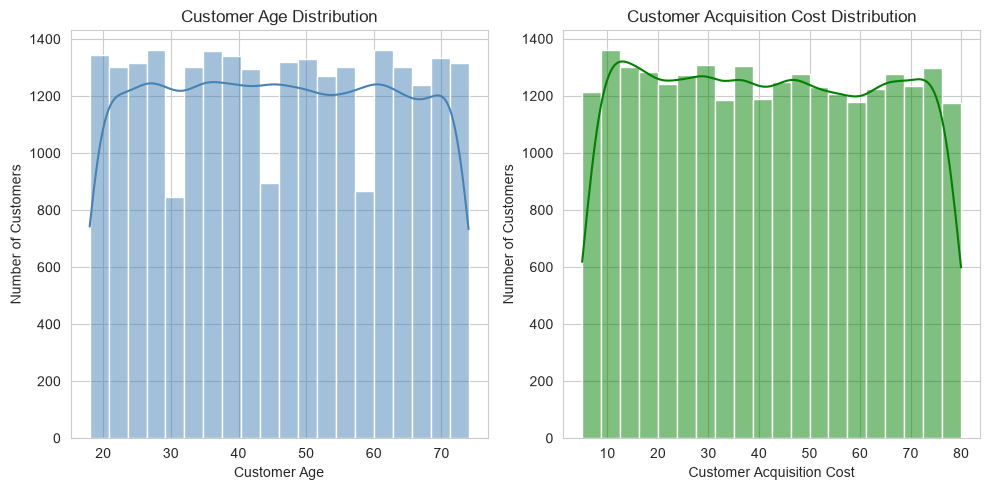

In [15]:
fig, axes=plt.subplots(1, 2)
sns.histplot(t["customer_age"],bins=20,kde=True,ax=axes[0],color="steelblue")
axes[0].set_title("Customer Age Distribution")
axes[0].set_xlabel("Customer Age")
axes[0].set_ylabel("Number of Customers")

sns.histplot(t['customer_acquisition_cost'],bins=20,kde=True,ax=axes[1],color="green")
axes[1].set_title("Customer Acquisition Cost Distribution")
axes[1].set_xlabel("Customer Acquisition Cost")
axes[1].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()


In [16]:
import warnings
warnings.filterwarnings("ignore")

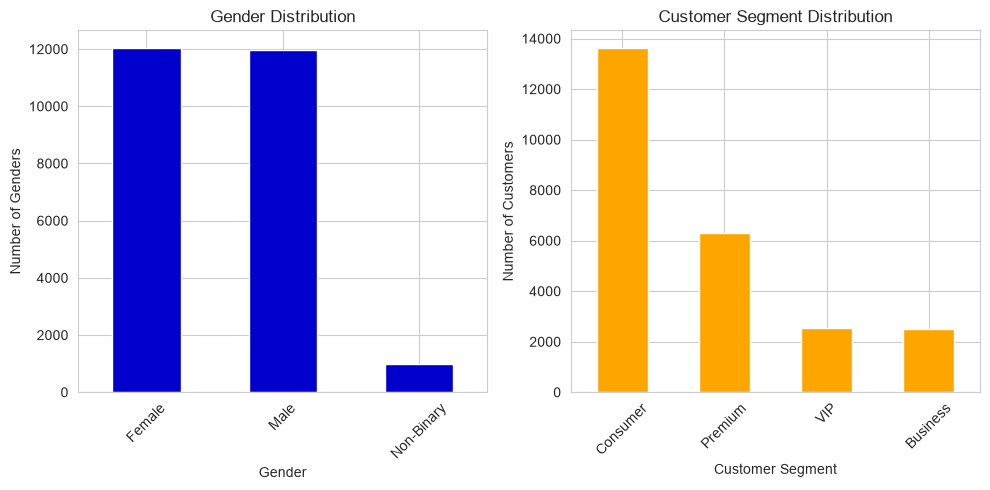

In [20]:
fig,axes=plt.subplots(1,2)

t["gender"].value_counts().plot(kind="bar",ax=axes[0],color="mediumblue")
axes[0].set_title("Gender Distribution")
axes[0].set_xlabel("Gender")
axes[0].tick_params(axis="x",rotation=45)
axes[0].set_ylabel("Number of Genders")



t["customer_segment"].value_counts().plot(kind="bar",ax=axes[1],color="orange")
axes[1].set_title("Customer Segment Distribution")
axes[1].set_xlabel("Customer Segment")
axes[1].tick_params(axis="x", rotation=45)
axes[1].set_ylabel("Number of Customers")
axes[1].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()


In [21]:
unique_ids=t["customer_id"].is_unique
duplicate_rows=t.duplicated().sum()
duplicate_names=t["customer_name"].duplicated().sum()

In [23]:
pd.Series({
    "customer id is unique (Ture or False)": unique_ids,
    "duplicate rows ": duplicate_rows,
    "duplicate name ": duplicate_names,
})

customer id is unique (Ture or False)    True
duplicate rows                              0
duplicate name                           3369
dtype: object

In [24]:
country_summary=t.groupby("customer_country").agg(
    customer_count=("customer_id", "count"),
    average_age=("customer_age", "mean"),
    avg_acquisition=("customer_acquisition_cost", "mean")
).sort_values("customer_count",ascending=False)

In [26]:
country_summary

,customer_count,average_age,avg_acquisition
customer_country,,,
USA,14925,45.928777,42.085881
UK,3701,45.883545,42.274712
Germany,2046,45.640762,42.217571
Canada,1279,46.275215,42.612651
Australia,1233,45.689376,42.972758
India,1041,46.024976,41.831585
UAE,775,45.909677,41.280594


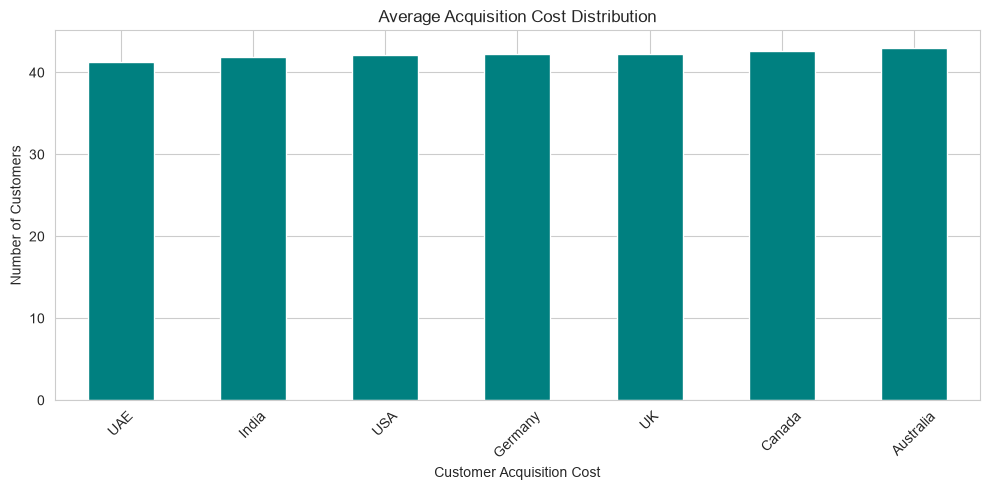

In [31]:
country_summary["avg_acquisition"].sort_values().plot(kind="bar",color="teal")
plt.title("Average Acquisition Cost Distribution")
plt.xlabel("Customer Acquisition Cost")
plt.xticks(rotation=45)
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

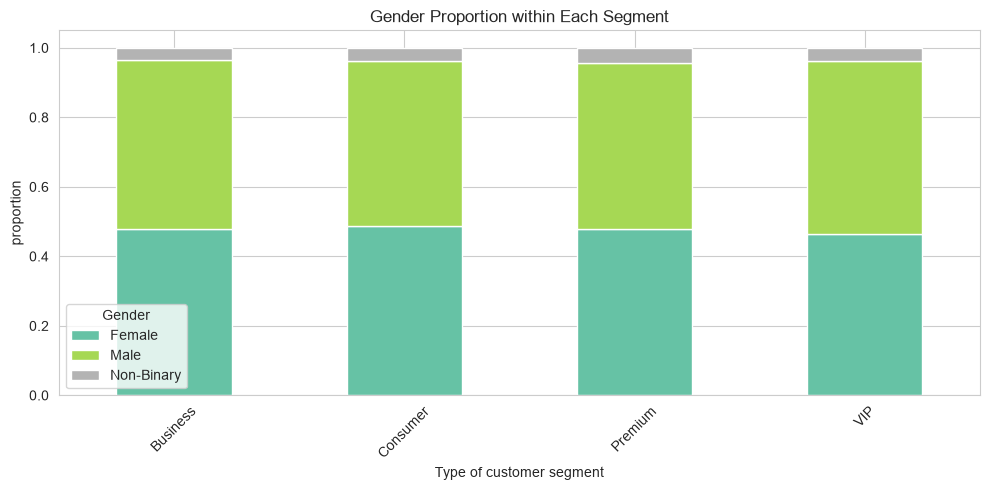

In [35]:
segment_gender=pd.crosstab(t["customer_segment"],t["gender"],normalize="index")
segment_gender.plot(kind="bar",stacked=True,colormap="Set2")
plt.title("Gender Proportion within Each Segment")
plt.xlabel("Type of customer segment")
plt.xticks(rotation=45)
plt.ylabel("proportion")
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

In [37]:
pivot=t.pivot_table(
    values="customer_acquisition_cost",
    index="region",
    columns="customer_segment",
    aggfunc="mean"
)

In [38]:
pivot

customer_segment,Business,Consumer,Premium,VIP
region,,,,
Central,42.665208,42.381241,42.033338,40.903996
East,41.582421,41.498164,42.068956,43.113654
North,43.024669,42.521355,42.938065,39.870359
South,42.419132,42.260161,41.927955,42.680490
West,42.257776,42.587711,41.129324,42.167195


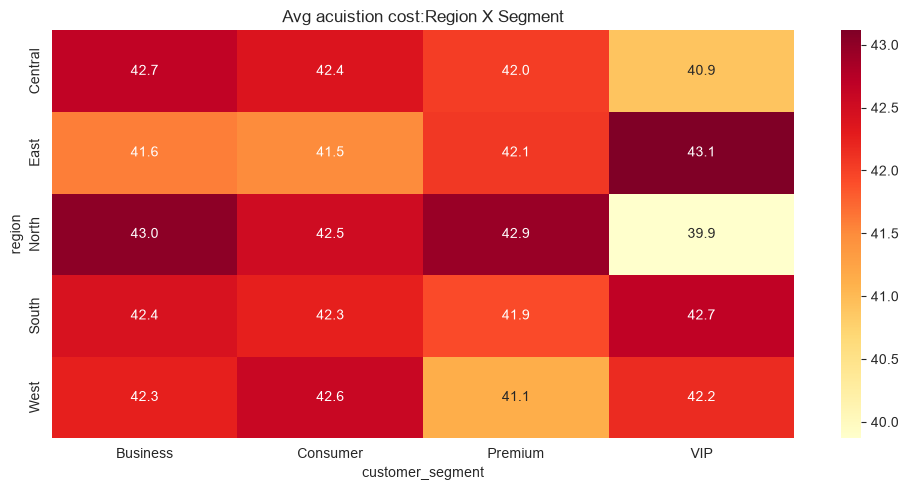

In [41]:
sns.heatmap(pivot,annot=True,fmt=".1f",cmap="YlOrRd")
plt.title("Avg acuistion cost:Region X Segment")

plt.tight_layout()
plt.show()

In [42]:
t["postal_len"]=t["customer_postal_code"].astype(str).str.len()

In [44]:
postal_by_country=pd.crosstab(t["customer_country"],t["postal_len"])

In [45]:
postal_by_country

postal_len,3,4,5
customer_country,,,
Australia,6,106,1121
Canada,7,124,1148
Germany,7,183,1856
India,2,91,948
UAE,3,56,716
UK,19,324,3358
USA,80,1368,13477


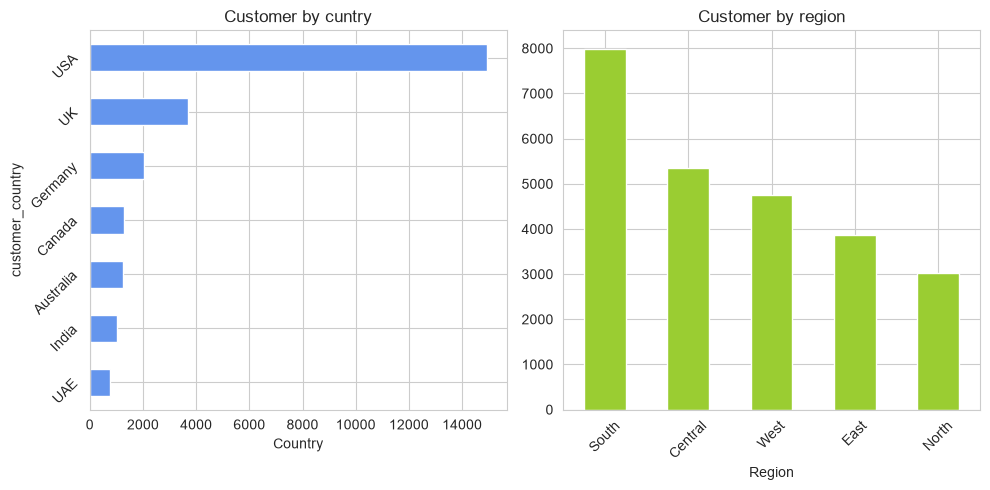

In [51]:
fig, axes=plt.subplots(1,2)

t["customer_country"].value_counts().plot(kind="barh",ax=axes[0],color="cornflowerblue")
axes[0].set_title("Customer by cuntry")
axes[0].set_xlabel("Country")
axes[0].tick_params(axis="y", labelrotation=45)
axes[0].invert_yaxis()


t["region"].value_counts().plot(kind="bar",ax=axes[1],color="yellowgreen")
axes[1].set_title("Customer by region")
axes[1].set_xlabel("Region")
axes[1].tick_params(axis="x", labelrotation=45)

plt.tight_layout()
plt.show()

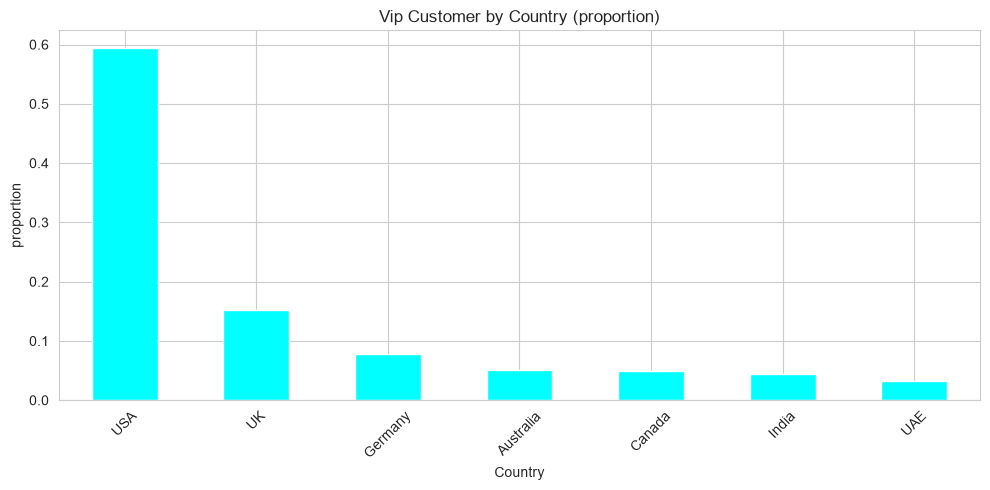

In [57]:
vip_by_country=t[t["customer_segment"]=="VIP"]["customer_country"].value_counts(normalize=True)

vip_by_country.plot(kind="bar",color="aqua")
plt.title("Vip Customer by Country (proportion)")
plt.xlabel("Country")
plt.xticks(rotation=45)
plt.ylabel("proportion")
plt.tight_layout()
plt.show()